# Pocket Cube · State-space search

This project models the 2×2×2 Pocket Cube as a graph: each configuration is a state, and each legal quarter-turn is an edge. The aim is to find a shortest sequence from a scrambled state to the solved state.

The notebook covers Q1–Q6, all five search versions, verification, and the required runtime, expansion, and storage plots. Run all cells from top to bottom in a fresh Python kernel. Plotting requires `matplotlib`; benchmarks at depths 10 and 11 can take several minutes.


## Cube representation and moves

The bottom-back-left corner is fixed, so the other seven corners are stored as `(perm, orient)`. `perm[i]` identifies the piece in slot `i`; `orient[i]` records its twist as 0, 1, or 2. Immutable tuples allow states to be used as dictionary keys.

The six moves are `U`, `U'`, `R`, `R'`, `F`, and `F'`. An apostrophe means a counter-clockwise quarter-turn. Each move returns a new state.

### Q1 and Q2 · Tuple trace and corner twists

Q1 follows the sequence `R U R'` from the solved state. Q2 checks that the orientation sum remains divisible by 3. A single corner twisted by hand changes this remainder, so legal face turns cannot solve that configuration.


In [1]:
# Solved Pocket Rubik's Cube
SOLVED_STATE = (
    (0, 1, 2, 3, 4, 5, 6),
    (0, 0, 0, 0, 0, 0, 0)
)

# Move definitions: (target positions, source positions, orientation changes)
MOVES = {
    "R": (
        (1, 2, 6, 5),
        (5, 1, 2, 6),
        (1, 2, 1, 2)
    ),


    "R'": (
        (1, 2, 6, 5),
        (2, 6, 5, 1),
        (1, 2, 1, 2)
    ),


    "U": (
        (0, 3, 2, 1),
        (1, 0, 3, 2),
        (0, 0, 0, 0)
    ),


    "U'": (
        (0, 3, 2, 1),
        (3, 2, 1, 0),
        (0, 0, 0, 0)
    ),

    
    "F": (
        (0, 1, 5, 4),
        (4, 0, 1, 5),
        (1, 2, 1, 2)
    ),


    "F'": (
        (0, 1, 5, 4),
        (1, 5, 4, 0),
        (1, 2, 1, 2)
    )
}


def apply_move(state, move):
    
    # Current permutation & orientation
    perm, orient = state

    # Whether the move exists
    if move not in MOVES:
        raise ValueError("Invalid move!")

    # Move instructions
    targets, sources, twists = MOVES[move]

    # Copies of the current state
    new_perm = list(perm)
    new_orient = list(orient)

    # Apply the movement to 4 corners
    for target, source, twist in zip(targets, sources, twists):

        # Move the corner cubie
        new_perm[target] = perm[source]

        # Update corner orientation
        new_orient[target] = (orient[source] + twist) % 3

    # Return a new immutable state
    return (
        tuple(new_perm),
        tuple(new_orient)
    )


def apply_sequence(state, moves):

    # Apply several moves one by one
    for move in moves:
        state = apply_move(state, move)

    return state


# Test Question #1
s0 = SOLVED_STATE
s1 = apply_move(s0, "R")
s2 = apply_move(s1, "U")
s3 = apply_move(s2, "R'")

print("-----------------------------------------------------------------------------------------------")
print("\t\t\tQUESTION #1")
print(f"Initial state: {s0}")
print(f"After R: {s1}")
print(f"After U: {s2}")
print(f"After R': {s3}")
print("-----------------------------------------------------------------------------------------------")


# Test Question #2
print("\t\t\tQUESTION #2")
for name, state in[
    ("s1", s1),
    ("s2", s2),
    ("s3", s3)
]:
    orientation_sum = sum(state[1])

    print(
        name,
        "Orientation sum:",
        orientation_sum,
        "Valid:",
        orientation_sum % 3 == 0
    )

# Test R followed by R'
test_state = apply_sequence(
    SOLVED_STATE, 
    ["R", "R'"]
)

assert test_state == SOLVED_STATE

print(f"R --> R': {test_state}")
print("\nAll tests passed!")
print("-----------------------------------------------------------------------------------------------")


-----------------------------------------------------------------------------------------------
			QUESTION #1
Initial state: ((0, 1, 2, 3, 4, 5, 6), (0, 0, 0, 0, 0, 0, 0))
After R: ((0, 5, 1, 3, 4, 6, 2), (0, 1, 2, 0, 0, 2, 1))
After U: ((5, 1, 3, 0, 4, 6, 2), (1, 2, 0, 0, 0, 2, 1))
After R': ((5, 3, 2, 0, 4, 1, 6), (1, 1, 0, 0, 0, 1, 0))
-----------------------------------------------------------------------------------------------
			QUESTION #2
s1 Orientation sum: 6 Valid: True
s2 Orientation sum: 6 Valid: True
s3 Orientation sum: 3 Valid: True
R --> R': ((0, 1, 2, 3, 4, 5, 6), (0, 0, 0, 0, 0, 0, 0))

All tests passed!
-----------------------------------------------------------------------------------------------


### Cube engine checks

Check the exact Q1 tuples, the orientation invariant, and move inverses on both solved and scrambled inputs. A single corner twisted by hand violates the invariant; this test detects the invalid configuration without attempting an exhaustive search.


In [2]:
from collections import deque

assert s1 == ((0, 5, 1, 3, 4, 6, 2), (0, 1, 2, 0, 0, 2, 1))
assert s2 == ((5, 1, 3, 0, 4, 6, 2), (1, 2, 0, 0, 0, 2, 1))
assert s3 == ((5, 3, 2, 0, 4, 1, 6), (1, 1, 0, 0, 0, 1, 0))
for state in (s0, s1, s2, s3):
    assert sum(state[1]) % 3 == 0

invalid_state = (SOLVED_STATE[0], (1, 0, 0, 0, 0, 0, 0))
assert sum(invalid_state[1]) % 3 != 0

for state in (SOLVED_STATE, s3):
    for move, undo in (("R", "R'"), ("U", "U'"), ("F", "F'")):
        assert apply_sequence(state, [move, undo]) == state
        assert apply_sequence(state, [undo, move]) == state
        assert apply_sequence(state, [move] * 4) == state
print("Q1 tuples, twist invariant, inverses, and four-turn checks passed.")


Q1 tuples, twist invariant, inverses, and four-turn checks passed.


## V1 · Sticker representation and unpruned DFS

V1 represents the cube as a mutable list of 24 sticker colors. Three sticker positions describe each corner, including the fixed corner. The move table permutes sticker positions; DFS does not call the tuple transition function during its search.

The stack stores sticker lists and copied move paths. There is no visited set or move pruning, and `max_depth` bounds the search. A returned path is valid but need not be shortest. The tests below compare the sticker engine with the tuple engine before running DFS.


In [3]:
# Each piece's three colors in twist order, starting with its U or D color.
CORNER_COLORS = ("ULF", "UFR", "URB", "UBL", "DFL", "DRF", "DBR", "DLB")


def state_to_stickers(state):
    """Turn (perm, orient) into a list of 24 sticker colors."""
    perm, orient = state
    stickers = []
    for slot in range(7):
        colors = CORNER_COLORS[perm[slot]]
        for k in range(3):
            stickers.append(colors[(k - orient[slot]) % 3])
    stickers.extend(CORNER_COLORS[7])  # The fixed corner.
    return stickers


# Sticker positions before each turn.
STICKER_SOURCE = {}
for move, (targets, sources, twists) in MOVES.items():
    source = list(range(24))
    for dest, src, twist in zip(targets, sources, twists):
        for k in range(3):
            source[3 * dest + k] = 3 * src + (k - twist) % 3
    STICKER_SOURCE[move] = source


def apply_move_to_stickers(stickers, move):
    """Do one move on a 24-sticker list (returns a new list)."""
    return [stickers[i] for i in STICKER_SOURCE[move]]

In [4]:
# Check single moves, inverse moves, and mixed sequences in both engines.
sequences = [[move] for move in MOVES] + [
    ["R", "U", "F"],
    ["R", "U", "R'"],
    ["F", "U'", "R", "F'"],
]
for state in (SOLVED_STATE, s3):
    for sequence in sequences:
        stickers = state_to_stickers(state)
        for move in sequence:
            stickers = apply_move_to_stickers(stickers, move)
        assert stickers == state_to_stickers(apply_sequence(state, sequence))
    for move, undo in (("R", "R'"), ("U", "U'"), ("F", "F'")):
        stickers = state_to_stickers(state)
        assert apply_move_to_stickers(apply_move_to_stickers(stickers, move), undo) == stickers
print("Sticker and tuple engines agree on individual moves and mixed sequences.")


Sticker and tuple engines agree on individual moves and mixed sequences.


In [5]:
def v1_dfs_unpruned(start, goal, max_depth):

    # Stack stores (24 sticker colors, moves used)
    goal_stickers = state_to_stickers(goal)
    stack = [(state_to_stickers(start), [])]

    # Count explored states
    explored = 0

    # Get all available moves
    moves = list(MOVES.keys())

    while stack:

        # Take the most recently added state
        stickers, path = stack.pop()

        explored += 1

        # Check whether the goal is found
        if stickers == goal_stickers:
            return path, explored

        # Do not search beyond maximum depth
        if len(path) >= max_depth:
            continue

        # Explore possible next moves
        for move in reversed(moves):

            new_stickers = apply_move_to_stickers(stickers, move)
            new_path = path + [move]

            stack.append((new_stickers, new_path))

    # No solution found within maximum depth
    return None, explored

## V2 · Unidirectional BFS

BFS uses a FIFO queue to explore states in increasing distance from the start. The parent dictionary both prevents repeated discoveries and records the moves needed to reconstruct a solution.

Because every quarter-turn has equal cost, the returned solution has the minimum number of moves. Its main limitation is the number of states retained as the search depth grows.


In [6]:
def v2_bfs_unidirectional(start, goal):

    # Queue stores states waiting to be explored
    queue = deque([start])

    # Remember where each state came from
    # This helps reconstruct the solution
    parent = {
        start: (None, None)
    }

    stats = {"expanded": 0, "moves_tried": 0, "max_stored": 1}

    # Get all available moves
    moves = list(MOVES.keys())

    while queue:

        # Remove the oldest state from the queue
        state = queue.popleft()


        # Check whether the goal is found
        if state == goal:

            # Reconstruct the solution path
            path = []
            current = state

            while parent[current][0] is not None:

                previous_state, move = parent[current]

                path.append(move)

                current = previous_state

            # Reverse the path into the correct order
            path.reverse()

            stats["max_stored"] = len(parent)
            return path, stats

        # Explore possible next moves
        stats["expanded"] += 1
        for move in moves:
            stats["moves_tried"] += 1

            new_state = apply_move(state, move)

            # Only visit states that have not been seen
            if new_state not in parent:

                parent[new_state] = (state, move)

                queue.append(new_state)

    # No solution found
    stats["max_stored"] = len(parent)
    return None, stats

### V1 and V2 · One-turn test

Both searches start from a cube scrambled by `R`. Applying each returned path checks solution validity; comparing lengths illustrates that depth-limited DFS can return a longer path than BFS.


In [7]:
# Create a scrambled cube using one move
test_start = apply_move(SOLVED_STATE, "R")

# The goal is the solved cube
test_goal = SOLVED_STATE

print("Starting scrambled cube:", test_start)
print("Goal cube:", test_goal)

# Run DFS with a depth limit
dfs_path, dfs_explored = v1_dfs_unpruned(
    test_start,
    test_goal,
    max_depth=5
)

# Run BFS
bfs_path, bfs_stats = v2_bfs_unidirectional(
    test_start,
    test_goal
)

# Display DFS results
print("\n========== DFS RESULTS ==========")

print("Solution:", dfs_path)

print(
    "Number of moves:",
    len(dfs_path) if dfs_path is not None else None
)

print("States explored:", dfs_explored)


# Display BFS results
print("\n========== BFS RESULTS ==========")

print("Solution:", bfs_path)

print(
    "Number of moves:",
    len(bfs_path) if bfs_path is not None else None
)

print("States expanded:", bfs_stats["expanded"])
print("Moves tried:", bfs_stats["moves_tried"])
print("Peak stored:", bfs_stats["max_stored"])
# Verify DFS solution

if dfs_path is not None:

    dfs_result = apply_sequence(
        test_start,
        dfs_path
    )

    print(
        "DFS reaches solved cube:",
        dfs_result == test_goal
    )

    assert dfs_result == test_goal

else:
    print("DFS did not find a solution.")


# Verify BFS solution

if bfs_path is not None:

    bfs_result = apply_sequence(
        test_start,
        bfs_path
    )

    print(
        "BFS reaches solved cube:",
        bfs_result == test_goal
    )

    assert bfs_result == test_goal

else:
    print("BFS did not find a solution.")


# Compare solution lengths
if dfs_path is not None and bfs_path is not None:

    print("\n========== COMPARISON ==========")

    print("DFS solution length:", len(dfs_path))
    print("BFS solution length:", len(bfs_path))

    print(
        "BFS solution is no longer than DFS:",
        len(bfs_path) <= len(dfs_path)
    )

print("\nAll available solution paths verified!")

Starting scrambled cube: ((0, 5, 1, 3, 4, 6, 2), (0, 1, 2, 0, 0, 2, 1))
Goal cube: ((0, 1, 2, 3, 4, 5, 6), (0, 0, 0, 0, 0, 0, 0))

========== DFS RESULTS ==========
Solution: ['R', 'R', 'R']
Number of moves: 3
States explored: 4

========== BFS RESULTS ==========
Solution: ["R'"]
Number of moves: 1
States expanded: 2
Moves tried: 12
Peak stored: 12
DFS reaches solved cube: True
BFS reaches solved cube: True

========== COMPARISON ==========
DFS solution length: 3
BFS solution length: 1
BFS solution is no longer than DFS: True

All available solution paths verified!


## Q3 · Path counts at depth 12

The question specifies these final-level move-tree counts:

| Model | Calculation |
|---|---:|
| V2: six choices on every turn | `6 ** 12` |
| V3: six first moves, then four moves on other faces | `6 * 4 ** 11` |
| V4: two searches, each six turns deep | `2 * (6 * 4 ** 5)` |

These are theoretical path counts, not unique cube states or measured solver work. The face-alternating model is the assumption supplied for Q3; the quarter-turn implementations below retain necessary half-turns such as `R R`. The ratio therefore compares the stated models rather than measured runtime.


In [8]:
# Q3 model counts
n2 = 6 ** 12
n3 = 6 * 4 ** 11
n4 = 2 * (6 * 4 ** 5)

print("Q3 — Model path counts")
print(f"N2 = {n2:,}")
print(f"N3 = {n3:,}")
print(f"N4 = {n4:,}")
print(f"N2 / N4 = {n2 // n4:,}")

Q3 — Model path counts
N2 = 2,176,782,336
N3 = 25,165,824
N4 = 12,288
N2 / N4 = 177,147


## V3 and V4 · Search helpers

A fixed move order makes the searches reproducible. `INVERSE` maps each turn to its undo, while `rebuild_path()` follows parent links and reverses the recorded moves into execution order.

`is_redundant()` rejects an immediate inverse and a third identical turn. Two identical turns are kept because they represent a half-turn.


In [9]:
# Search helpers
from collections import deque

# My move order for both searches
MOVE_ORDER = ("U", "U'", "R", "R'", "F", "F'")
INVERSE = {
    "U": "U'", "U'": "U",
    "R": "R'", "R'": "R",
    "F": "F'", "F'": "F",
}


def rebuild_path(parent, state):
    """Rebuild moves from parent links."""
    path = []
    while parent[state] is not None:
        state, move = parent[state]
        path.append(move)
    # Reverse my backtracked moves
    path.reverse()
    return path


def is_redundant(move, last_move, repeats):
    """Check for a redundant move."""
    if last_move is None:
        return False
    if move == INVERSE[last_move]:
        return True
    if move == last_move and repeats == 2:
        return True
    return False

### V3 · Move-pruned BFS

V3 keeps BFS layer order and removes move sequences that can be shortened:

- `R R'` is skipped because the turns cancel.
- `R R R` is skipped because one `R'` reaches the same state.
- `R R` is kept because it is a valid two-quarter-turn half-turn.

Queue entries carry the cube state, last move, and repeat count. The parent dictionary records discoveries and reconstructs the shortest solution.


In [10]:
# V3 · Move-pruned BFS
def v3_bfs_move_pruned(start, goal):
    """Return the shortest path and search stats."""
    stats = {"expanded": 0, "moves_tried": 0, "max_stored": 1}
    if start == goal:
        return [], stats

    parent = {start: None}
    # Queue entry: state, last move, streak
    queue = deque([(start, None, 0)])

    while queue:
        state, last_move, repeats = queue.popleft()
        stats["expanded"] += 1
        for move in MOVE_ORDER:
            if is_redundant(move, last_move, repeats):
                continue
            new_state = apply_move(state, move)
            stats["moves_tried"] += 1
            if new_state not in parent:
                parent[new_state] = (state, move)
                if new_state == goal:
                    stats["max_stored"] = len(parent)
                    return rebuild_path(parent, new_state), stats
                new_repeats = repeats + 1 if move == last_move else 1
                queue.append((new_state, move, new_repeats))
    stats["max_stored"] = len(parent)
    return None, stats

### Q4 · Hand trace

```text
Scramble side    s3 --R--> s2
Goal side        s0 --R--> s1 --U--> s2
```

Meet at **s₂**. Reverse and undo the goal-side turns `R U` to get `U′ R′`. Add the forward `R` for **`R U′ R′`**.

In [11]:
# My Q4 hand trace
forward_moves = ["R"]       # s3 -> s2
backward_moves = ["R", "U"]   # solved -> s1 -> s2
assert apply_sequence(s3, forward_moves) == s2
assert apply_sequence(SOLVED_STATE, backward_moves) == s2

# Reverse and undo the goal-side moves
finish_moves = [INVERSE[move] for move in reversed(backward_moves)]
hand_solution = forward_moves + finish_moves
assert apply_sequence(s3, hand_solution) == SOLVED_STATE

print("\nQ4 — Hand trace")
print("Scramble side: s3 --R--> s2")
print("Goal side:     s0 --R--> s1 --U--> s2")
print("Meeting state s2 =", s2)
print("Solution =", " ".join(hand_solution))


Q4 — Hand trace
Scramble side: s3 --R--> s2
Goal side:     s0 --R--> s1 --U--> s2
Meeting state s2 = ((5, 1, 3, 0, 4, 6, 2), (1, 2, 0, 0, 0, 2, 1))
Solution = R U' R'


### V4 · Bidirectional BFS

V4 searches from both the scrambled state and the goal, alternating complete BFS layers. Each side has its own parent dictionary and move history, and both sides apply V3's safe pruning.

When the searches first overlap, the forward path is joined to the reversed and inverted goal-side path. Searching roughly half the solution depth from each end reduces the size of the frontiers.

The hand trace meets at `s2`; the alternating code demonstration meets at `s1`. Both reconstruct the same shortest solution.


In [12]:
# V4 · Bidirectional BFS
def expand_one_level(frontier, parent, other_parent, stats):
    """Expand one layer using V3 move pruning and collect meetings."""
    next_ring = []
    meetings = []
    for state, last_move, repeats in frontier:
        stats["expanded"] += 1
        for move in MOVE_ORDER:
            if is_redundant(move, last_move, repeats):
                continue
            new_state = apply_move(state, move)
            stats["moves_tried"] += 1
            if new_state in parent:
                continue
            parent[new_state] = (state, move)
            new_repeats = repeats + 1 if move == last_move else 1
            next_ring.append((new_state, move, new_repeats))
            if new_state in other_parent:
                meetings.append(new_state)
    return next_ring, meetings


def v4_bfs_bidirectional(start, goal):
    """Return the shortest path and search stats."""
    stats = {"expanded": 0, "moves_tried": 0, "max_stored": 1, "meeting_state": None}
    if start == goal:
        stats["meeting_state"] = start
        return [], stats

    # Each side carries its own move history for safe local pruning.
    parent_f, ring_f = {start: None}, [(start, None, 0)]
    parent_b, ring_b = {goal: None}, [(goal, None, 0)]
    forward_turn = True
    stats["max_stored"] = 2

    while ring_f and ring_b:
        if forward_turn:
            ring_f, meetings = expand_one_level(ring_f, parent_f, parent_b, stats)
        else:
            ring_b, meetings = expand_one_level(ring_b, parent_b, parent_f, stats)
        stats["max_stored"] = len(parent_f) + len(parent_b)

        if meetings:
            meet = min(meetings)
            stats["meeting_state"] = meet
            start_to_meet = rebuild_path(parent_f, meet)
            goal_to_meet = rebuild_path(parent_b, meet)
            # Reverse and undo my goal-side moves
            meet_to_goal = [INVERSE[move] for move in reversed(goal_to_meet)]
            return start_to_meet + meet_to_goal, stats

        forward_turn = not forward_turn
    return None, stats

### Solver comparison

Use the same scramble, `R U R'`, for V2–V4 and verify a three-move solution. A state is **expanded** when its outgoing moves are attempted; goal states returned without trying their moves are not counted as expanded. Move attempts are counted separately.

V2 checks the goal on dequeue, whereas V3 checks on discovery. These implementation differences contribute to the measured work. V4 alternates complete layers. The regression checks also cover solved input, half-turns in both directions, and V4's actual pruning.


In [13]:
print("Scramble: R U R'")
for solve in (v2_bfs_unidirectional, v3_bfs_move_pruned, v4_bfs_bidirectional):
    path, details = solve(s3, SOLVED_STATE)
    assert path == ["R", "U'", "R'"]
    assert apply_sequence(s3, path) == SOLVED_STATE
    print(solve.__name__, "solution:", path)
    print("Search count/stats:", details)

_, v4_stats = v4_bfs_bidirectional(s3, SOLVED_STATE)
assert v4_stats["meeting_state"] == s1
print("V4 code meets at s1.")


Scramble: R U R'
v2_bfs_unidirectional solution: ['R', "U'", "R'"]
Search count/stats: {'expanded': 44, 'moves_tried': 264, 'max_stored': 199}
v3_bfs_move_pruned solution: ['R', "U'", "R'"]
Search count/stats: {'expanded': 18, 'moves_tried': 88, 'max_stored': 81}
v4_bfs_bidirectional solution: ['R', "U'", "R'"]
Search count/stats: {'expanded': 8, 'moves_tried': 42, 'max_stored': 41, 'meeting_state': ((0, 5, 1, 3, 4, 6, 2), (0, 1, 2, 0, 0, 2, 1))}
V4 code meets at s1.


In [14]:
# V4 regression checks: solved input, half-turns, and both search directions.
path, _ = v4_bfs_bidirectional(SOLVED_STATE, SOLVED_STATE)
assert path == []
for face in ("U", "R", "F"):
    half_turn = apply_sequence(SOLVED_STATE, [face, face])
    for start, goal in ((half_turn, SOLVED_STATE), (SOLVED_STATE, half_turn)):
        path, _ = v4_bfs_bidirectional(start, goal)
        reference, _ = v2_bfs_unidirectional(start, goal)
        assert len(path) == len(reference) == 2
        assert apply_sequence(start, path) == goal

    # Check the shared expansion helper actually skips redundant move attempts.
    for repeats, expected_attempts in ((1, 5), (2, 4)):
        state = apply_sequence(SOLVED_STATE, [face] * repeats)
        stats = {"expanded": 0, "moves_tried": 0}
        ring, meetings = expand_one_level(
            [(state, face, repeats)], {state: None}, {}, stats
        )
        assert stats["moves_tried"] == expected_attempts
        assert all(not is_redundant(move, face, repeats) for _, move, _ in ring)
print("V4 solved-state, half-turn, and move-pruning regression checks passed.")


V4 solved-state, half-turn, and move-pruning regression checks passed.


## Q5 · Corner heuristic

Count a corner once if it is displaced or twisted. One face turn affects at most four corners, so `ceil(wrong / 4)` is a lower bound on the remaining number of moves.

After one `R` turn, four corners are affected: the unscaled count is 4 and the heuristic is 1. Using 4 directly would overestimate a state that can be solved in one move.


In [15]:
import math

def heuristic(state, goal):
    # number of corners in the wrong slot or twisted, divided by 4 (rounded up)
    wrong = sum(1 for i in range(7) if state[0][i] != goal[0][i] or state[1][i] != goal[1][i])
    return math.ceil(wrong / 4)

def inverse(move):
    # R <-> R'
    if move.endswith("'"):
        return move[0]
    return move + "'"

In [16]:
assert heuristic(SOLVED_STATE, SOLVED_STATE) == 0
assert heuristic(s1, SOLVED_STATE) == 1
assert heuristic(s3, SOLVED_STATE) <= 3
print("Heuristic checks passed.")


Heuristic checks passed.


## V5 · IDA*

IDA* performs depth-first searches bounded by `f = g + h`. Here `g` is the number of moves used and `h` is an admissible estimate of the remaining distance. Start at `h(start)` and increase the threshold to the smallest rejected `f` value after an unsuccessful round.

Only the current path and recursion stack are retained. Immediate inverse moves are skipped. The threshold cap of 14 covers legal fixed-corner Pocket Cube states in the quarter-turn metric. Statistics count expansions and move attempts separately; peak storage is the maximum number of simultaneously active recursive search calls, including the root and calls rejected by the threshold.


In [17]:
def v5_ida_star(start, goal):
    path = []
    stats = {"expanded": 0, "moves_tried": 0, "max_stored": 0}

    def search(state, g, T):
        # Include the current state on the recursion stack.
        stats["max_stored"] = max(stats["max_stored"], g + 1)
        f = g + heuristic(state, goal)
        if f > T:
            return f                      # too long: cut this branch
        if state == goal:
            return "FOUND"
        stats["expanded"] += 1
        smallest = math.inf
        for move in MOVES:
            if path and move == inverse(path[-1]):
                continue                  # don't undo the last move
            stats["moves_tried"] += 1
            path.append(move)
            result = search(apply_move(state, move), g + 1, T)
            if result == "FOUND":
                return "FOUND"
            path.pop()
            smallest = min(smallest, result)
        return smallest

    T = heuristic(start, goal)
    while T <= 14:                        # 14 = longest possible solution
        result = search(start, 0, T)
        if result == "FOUND":
            return path, stats
        T = result                        # try again with a bigger limit
    return None, stats

### Hand-trace check

The heuristic should return 1 for `s1`. IDA* is also checked on the same three-move scramble used in Q4, allowing its result to be compared with the BFS solutions.


In [18]:
s1 = apply_move(SOLVED_STATE, "R")
s2 = apply_move(s1, "U")
s3 = apply_move(s2, "R'")

path, stats = v5_ida_star(s3, SOLVED_STATE)
assert path == ["R", "U'", "R'"]
assert apply_sequence(s3, path) == SOLVED_STATE
print("h(s1) =", heuristic(s1, SOLVED_STATE))
print("V5 on s3:", path)
print("V5 stats:", stats)


h(s1) = 1
V5 on s3: ['R', "U'", "R'"]
V5 stats: {'expanded': 7, 'moves_tried': 28, 'max_stored': 4}


## Q6 · Five-stage complexity comparison

`d` is the shortest solution length and `D` is the DFS depth cap. These are conservative move-tree upper bounds for the implemented algorithms, with a fixed-size cube representation. `I` is the number of IDA* threshold rounds; integer move costs and heuristic values give at most `d + 1` rounds for a solvable state.

| Version | Primary data structures | Time upper bound | Peak space | Shortest? |
|---|---|---|---|---|
| V1: unpruned DFS | 24-sticker lists and copied paths on a stack | `O(D × 6^D)` | `O(D²)` | No |
| V2: BFS | FIFO queue and parent dictionary | `O(6^d)` | `O(6^d)` | Yes |
| V3: pruned BFS | Queue with move history and parent dictionary | `O(5^d)` | `O(5^d)` | Yes |
| V4: bidirectional pruned BFS | Two layers with move history and two parent dictionaries | `O(5^ceil(d/2))` | `O(5^ceil(d/2))` | Yes |
| V5: IDA* | Current path and recursion stack | `O(I × 5^d)` | `O(d)` | Yes |

V1 copies a path for each pending branch, giving the extra depth factors shown. V3–V5 allow at most five move attempts after the first turn, while retaining half-turns. V4 searches to at most `ceil(d/2)` on either side. V5's bound explicitly includes repeated threshold rounds; substituting `I ≤ d + 1` gives a conservative `O(d × 5^d)` bound for positive `d`.

Q3 uses the separately specified face-alternating counting model, whose ideal tree bounds are `O(4^d)` and `O(4^ceil(d/2))`. That model is distinct from retaining two quarter-turns on the same face in the implementation. The graph searches also avoid duplicate discoveries, so measured work can be much smaller than tree bounds.


## Verification suite

Generate 20 random cases at each **true shortest depth** from 1 through 6, giving 120 cases. Ordinary BFS independently determines these shallow depths. V1 must return a valid path within the cap, while V2–V5 must solve the cube and agree on the exact shortest length.

Additional checks cover the solved input and half-turns for all four optimal solvers. The reported storage counts are checked on solved input: one root state for each solver. Cases can repeat at shallow depths, where few states exist.


In [19]:
import random

def random_scramble(depth, rng):
    moves = []
    while len(moves) < depth:
        move = rng.choice(MOVE_ORDER)
        if not moves or move != INVERSE[moves[-1]]:
            moves.append(move)
    return moves


def scramble_at_depth(depth, rng, reference=v2_bfs_unidirectional):
    while True:
        start = apply_sequence(SOLVED_STATE, random_scramble(depth, rng))
        path, _ = reference(start, SOLVED_STATE)
        if path is not None and len(path) == depth:
            return start


optimal_solvers = {
    "V2 BFS": v2_bfs_unidirectional,
    "V3 pruned BFS": v3_bfs_move_pruned,
    "V4 bidirectional BFS": v4_bfs_bidirectional,
    "V5 IDA*": v5_ida_star,
}

for name, solve in optimal_solvers.items():
    path, stats = solve(SOLVED_STATE, SOLVED_STATE)
    assert path == [] and stats["expanded"] == stats["moves_tried"] == 0
    assert stats["max_stored"] == 1
    for face in ("U", "R", "F"):
        start = apply_sequence(SOLVED_STATE, [face, face])
        path, _ = solve(start, SOLVED_STATE)
        assert path is not None and len(path) == 2, (name, face)
        assert apply_sequence(start, path) == SOLVED_STATE

rng = random.Random(42)
verification_total = 0
for depth in range(1, 7):
    for _ in range(20):
        start = scramble_at_depth(depth, rng)
        for name, solve in optimal_solvers.items():
            path, stats = solve(start, SOLVED_STATE)
            assert path is not None and len(path) == depth, (name, depth, path)
            assert apply_sequence(start, path) == SOLVED_STATE, (name, depth)
        path, _ = v1_dfs_unpruned(start, SOLVED_STATE, max_depth=depth)
        assert path is not None and apply_sequence(start, path) == SOLVED_STATE
        verification_total += 1
    print(f"Depth {depth}: 20 trials passed.")
print(f"{verification_total} total trials passed.")


Depth 1: 20 trials passed.
Depth 2: 20 trials passed.
Depth 3: 20 trials passed.
Depth 4: 20 trials passed.
Depth 5: 20 trials passed.
Depth 6: 20 trials passed.
120 total trials passed.


## Benchmarks and plots

Use two distinct shared starting cubes at each true solution depth in `[2, 4, 6, 8, 10, 11]`. V4 filters candidate depths efficiently; the benchmark's ordinary BFS run independently confirms the depth of every selected cube, and all solvers must agree. Candidate generation is outside the timing interval.

Each measured solver call returns its own statistics, so no move-counting wrapper or memory tracer is included in the timing. Report average expanded states and average wall-clock time across the two cubes. Report the largest peak storage observed across those runs.

- **Expanded:** a search state whose outgoing moves are attempted. IDA* counts repeated expansions across threshold rounds.
- **Moves tried:** calls to the transition function after pruning, reported separately from expansions.
- **Peak storage:** parent-dictionary entries for V2–V4, summing both sides for V4; active recursive search calls for V5. These are the storage measures requested by the assignment, rather than byte measurements of process RAM.

Two cubes give a small empirical sample; results describe these cases rather than all cubes at each depth.


In [20]:
import time

DEPTHS = [2, 4, 6, 8, 10, 11]
SCRAMBLES_PER_DEPTH = 2
rng = random.Random(2026)
results = {name: {} for name in optimal_solvers}
benchmark_starts = {}

for depth in DEPTHS:
    starts = []
    while len(starts) < SCRAMBLES_PER_DEPTH:
        start = scramble_at_depth(depth, rng, reference=v4_bfs_bidirectional)
        if start not in starts:
            starts.append(start)
    benchmark_starts[depth] = starts

    print(f"Depth {depth}", flush=True)
    for name, solve in optimal_solvers.items():
        runs = []
        for start in starts:
            t0 = time.perf_counter()
            path, stats = solve(start, SOLVED_STATE)
            seconds = time.perf_counter() - t0
            assert path is not None and len(path) == depth, (name, depth)
            assert apply_sequence(start, path) == SOLVED_STATE, (name, depth)
            runs.append({
                "seconds": seconds,
                "expanded": stats["expanded"],
                "moves_tried": stats["moves_tried"],
                "stored": stats["max_stored"],
            })

        results[name][depth] = {
            "expanded": sum(run["expanded"] for run in runs) / len(runs),
            "seconds": sum(run["seconds"] for run in runs) / len(runs),
            "stored": max(run["stored"] for run in runs),
            "runs": runs,
        }
        row = results[name][depth]
        print(
            f"  {name}: {row['expanded']:,.1f} expanded | "
            f"{row['seconds']:.5f} s | {row['stored']:,} peak stored",
            flush=True,
        )


Depth 2
  V2 BFS: 21.0 expanded | 0.00011 s | 132 peak stored
  V3 pruned BFS: 5.5 expanded | 0.00003 s | 30 peak stored
  V4 bidirectional BFS: 2.0 expanded | 0.00002 s | 14 peak stored
  V5 IDA*: 2.5 expanded | 0.00003 s | 3 peak stored
Depth 4
  V2 BFS: 600.0 expanded | 0.00345 s | 2,619 peak stored
  V3 pruned BFS: 134.5 expanded | 0.00064 s | 604 peak stored
  V4 bidirectional BFS: 14.0 expanded | 0.00008 s | 68 peak stored
  V5 IDA*: 45.0 expanded | 0.00041 s | 5 peak stored
Depth 6
  V2 BFS: 9,722.0 expanded | 0.06411 s | 43,181 peak stored
  V3 pruned BFS: 1,908.5 expanded | 0.01133 s | 10,863 peak stored
  V4 bidirectional BFS: 68.0 expanded | 0.00034 s | 308 peak stored
  V5 IDA*: 963.0 expanded | 0.00925 s | 7 peak stored
Depth 8
  V2 BFS: 87,009.0 expanded | 0.87325 s | 303,673 peak stored
  V3 pruned BFS: 24,058.5 expanded | 0.21126 s | 127,262 peak stored
  V4 bidirectional BFS: 308.0 expanded | 0.00204 s | 1,376 peak stored
  V5 IDA*: 13,430.5 expanded | 0.12307 s | 9 pe

### Plot 1 · Expanded states and runtime

Both panels use a base-10 logarithmic vertical axis. Each point averages the same two cubes for every solver at that depth. Timing differences include each implementation's move order, goal-check placement, and data-structure overhead.


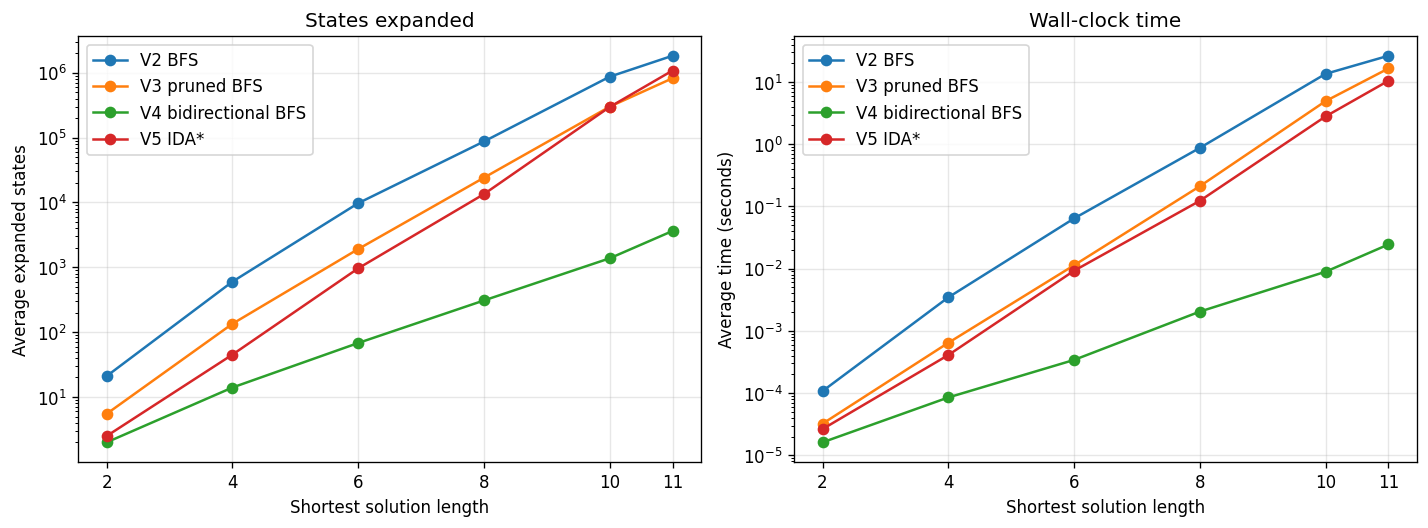

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, rows in results.items():
    axes[0].plot(DEPTHS, [rows[d]["expanded"] for d in DEPTHS], "o-", label=name)
    axes[1].plot(DEPTHS, [rows[d]["seconds"] for d in DEPTHS], "o-", label=name)

axes[0].set_title("States expanded")
axes[0].set_ylabel("Average expanded states")
axes[1].set_title("Wall-clock time")
axes[1].set_ylabel("Average time (seconds)")
for ax in axes:
    ax.set_yscale("log", base=10)
    ax.set_xlabel("Shortest solution length")
    ax.set_xticks(DEPTHS)
    ax.grid(True, which="major", alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()


### Plot 2 · Peak search storage

For each solver and depth, plot the larger peak from the two measured runs. Dictionary entries and active recursion calls are different storage units; the plot shows the assignment's requested comparison of retained search states rather than equal amounts of RAM.


V2 BFS at depth 11: 3,512,840 peak stored
V3 pruned BFS at depth 11: 2,514,060 peak stored
V4 bidirectional BFS at depth 11: 14,857 peak stored
V5 IDA* at depth 11: 12 peak stored


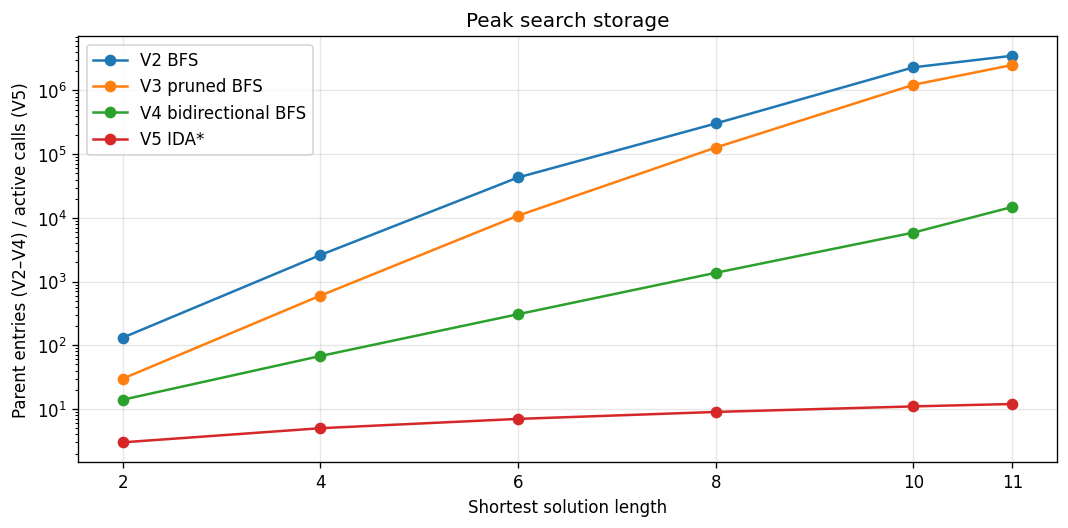

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, rows in results.items():
    ax.plot(DEPTHS, [rows[d]["stored"] for d in DEPTHS], "o-", label=name)

ax.set_title("Peak search storage")
ax.set_xlabel("Shortest solution length")
ax.set_ylabel("Parent entries (V2–V4) / active calls (V5)")
ax.set_yscale("log", base=10)
ax.set_xticks(DEPTHS)
ax.grid(True, which="major", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

for name, rows in results.items():
    print(f"{name} at depth 11: {rows[11]['stored']:,} peak stored")
